**Лабораторная выполнена в окружении `Python (NIR experiment)` с использованием CUDA. Фактическое устройство и версии библиотек выводятся в ячейке импорта.**

# **Практическое занятие: RNN, LSTM и GRU**

В этом блокноте мы проведём эксперименты с рекуррентными сетями, чтобы на практике увидеть, как они справляются с долгосрочными зависимостями и как LSTM/GRU решают проблему затухающих градиентов. Мы используем PyTorch и Google Colab.

**План практики:**
1. **Adding problem** – синтетическая задача, требующая запоминания информации на большом расстоянии. Сравним vanilla RNN, LSTM и GRU, визуализируем градиенты.
2. **Классификация тональности на русском языке** – используем датасет RuSentiment, построим BiLSTM, сравним однонаправленную и двунаправленную модели, визуализируем скрытые состояния через t-SNE.

👉 *Инструкция:* Запускайте ячейки последовательно, меняйте гиперпараметры, где предложено, и отвечайте на вопросы для интерпретации.

## **1. Установка и импорт библиотек**

In [1]:
# Зависимости уже установлены в окружении Python (NIR experiment).
# Выводим версии, не изменяя окружение во время воспроизводимого запуска ноутбука.
from importlib.metadata import version

for package in ("torch", "numpy", "datasets", "scikit-learn", "matplotlib", "seaborn"):
    print(f"{package}: {version(package)}")

torch: 2.5.1+cu124
numpy: 1.26.4
datasets: 4.8.3
scikit-learn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2


In [2]:
import sys
import warnings
warnings.filterwarnings('ignore')
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer
from tqdm import tqdm
import random

# Для воспроизводимости
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Python: {sys.executable}')
print(f'Using device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}; CUDA: {torch.version.cuda}')

Python: C:\Users\1\AAA_Notebooks\Syntactic parser\.venv\Scripts\python.exe
Using device: cuda
GPU: NVIDIA GeForce GTX 1650; CUDA: 12.4


## **2. Эксперимент 1: Adding problem (задача на долгосрочные зависимости)**

**Описание задачи:** Даётся последовательность случайных чисел $x_1, \dots, x_T$ (обычно T=100) и два индекса $i$ и $j$ (первый в первой половине, второй – во второй). Цель – рассчитать сумму $x_i + x_j$. Модель должна запомнить значения на больших расстояниях.

Мы сравним три модели: **vanilla RNN**, **LSTM**, **GRU**. Будем отслеживать:
- потери на валидации
- нормы градиентов для разных шагов времени (чтобы увидеть затухание)

Здесь формируются numpy вектора на выходе.

In [3]:
def generate_adding_problem_data(num_samples, seq_len=100):
    """
    Генерирует синтетический датасет для adding problem.
    Возвращает: X (num_samples, seq_len, 2) — канал значений и бинарный канал-маску,
                y (num_samples) — сумму двух отмеченных чисел.
    """
    values = np.random.uniform(0, 1, (num_samples, seq_len)).astype(np.float32)
    markers = np.zeros((num_samples, seq_len), dtype=np.float32)
    y = np.zeros(num_samples, dtype=np.float32)

    for i in range(num_samples):
        idx1 = np.random.randint(0, seq_len // 2)
        idx2 = np.random.randint(seq_len // 2, seq_len)
        markers[i, [idx1, idx2]] = 1.0
        y[i] = values[i, idx1] + values[i, idx2]

    X = np.stack((values, markers), axis=-1)
    return X, y

# Генерируем train и val
seq_len = 100
train_X, train_y = generate_adding_problem_data(5000, seq_len)
val_X, val_y = generate_adding_problem_data(1000, seq_len)

print(f'Train shape: {train_X.shape}, Val shape: {val_X.shape}')
print(f'Число маркеров в каждой последовательности: {np.unique(train_X[:, :, 1].sum(axis=1))}')

Train shape: (5000, 100, 2), Val shape: (1000, 100, 2)
Число маркеров в каждой последовательности: [2.]


Преобразуем массивы NumPy в тензоры PyTorch и создаём загрузчики данных для обучения и валидации.

In [4]:
class AddingDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X)
        self.y = torch.tensor(y).unsqueeze(1)  # для MSE функция в PyTorch, которая добавляет новое измерение размером 1 к тензору в указанной позиции (индекс измерения)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]
batch_size = 128
train_dataset = AddingDataset(train_X, train_y)
val_dataset = AddingDataset(val_X, val_y)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

Построение классической рекуррентной нейросети

In [5]:
class VanillaRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        # Если batch_first = True, то входные и выходные тензоры имеют форму (batch_size, seq_len, input_size)
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True, nonlinearity='tanh')
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.rnn(x)  # out: (batch, seq_len, hidden)
        out = self.fc(out[:, -1, :])  # используем последний скрытый
        return out



In [6]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out



In [7]:
class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out

Реализация цикла обучения одной сети. Запоминает нормы градиентов

In [8]:
def train_model(model, train_loader, val_loader, epochs=20, lr=0.001, clip=1.0, use_scheduler=False):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    scheduler = None
    if use_scheduler:
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3, min_lr=1e-5)
        
    train_losses, val_losses = [], []
    grad_norms = []  # для отслеживания норм градиентов (по эпохам)

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            # clip_grad_norm_ возвращает норму до обрезки — именно её анализируем.
            total_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            grad_norms.append(float(total_norm))
            optimizer.step()
            total_loss += loss.item()
        train_losses.append(total_loss / len(train_loader))

        # Валидация
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                pred = model(X_batch)
                loss = criterion(pred, y_batch)
                val_loss += loss.item()
        val_losses.append(val_loss / len(val_loader))
        
        # Делаем шаг шедулера после валидации
        if scheduler is not None:
            scheduler.step(val_losses[-1])

        if (epoch+1) % 5 == 0:
            print(f'Epoch {epoch+1}: train_loss={train_losses[-1]:.4f}, val_loss={val_losses[-1]:.4f}')

    return train_losses, val_losses, grad_norms

Собственно обучение трёх сетей.
Осторожно! Работает долго.

In [9]:
input_size = 2
hidden_size = 128
output_size = 1
epochs = 30

print("Training Vanilla RNN...")
rnn_model = VanillaRNN(input_size, hidden_size, output_size)
rnn_train_loss, rnn_val_loss, rnn_grads = train_model(rnn_model, train_loader, val_loader, epochs=epochs, use_scheduler=True)

print("\nTraining LSTM...")
lstm_model = LSTMModel(input_size, hidden_size, output_size)
lstm_train_loss, lstm_val_loss, lstm_grads = train_model(lstm_model, train_loader, val_loader, epochs=epochs, use_scheduler=True)

print("\nTraining GRU...")
gru_model = GRUModel(input_size, hidden_size, output_size)
gru_train_loss, gru_val_loss, gru_grads = train_model(gru_model, train_loader, val_loader, epochs=epochs, use_scheduler=True)

Training Vanilla RNN...
Epoch 5: train_loss=0.1734, val_loss=0.1656
Epoch 10: train_loss=0.1692, val_loss=0.1632
Epoch 15: train_loss=0.1687, val_loss=0.1668
Epoch 20: train_loss=0.1661, val_loss=0.1634
Epoch 25: train_loss=0.1745, val_loss=0.1637
Epoch 30: train_loss=0.1670, val_loss=0.1635

Training LSTM...
Epoch 5: train_loss=0.1717, val_loss=0.1642
Epoch 10: train_loss=0.1748, val_loss=0.1655
Epoch 15: train_loss=0.1731, val_loss=0.1632
Epoch 20: train_loss=0.1704, val_loss=0.1632
Epoch 25: train_loss=0.1682, val_loss=0.1630
Epoch 30: train_loss=0.1695, val_loss=0.1651

Training GRU...
Epoch 5: train_loss=0.1740, val_loss=0.1629
Epoch 10: train_loss=0.1721, val_loss=0.1640
Epoch 15: train_loss=0.1630, val_loss=0.1594
Epoch 20: train_loss=0.0580, val_loss=0.0427
Epoch 25: train_loss=0.0062, val_loss=0.0056
Epoch 30: train_loss=0.0040, val_loss=0.0034


### **2.1. Визуализация результатов**

В нормах градиентов итерация - это эпоха + номер батча внутри эпохи.

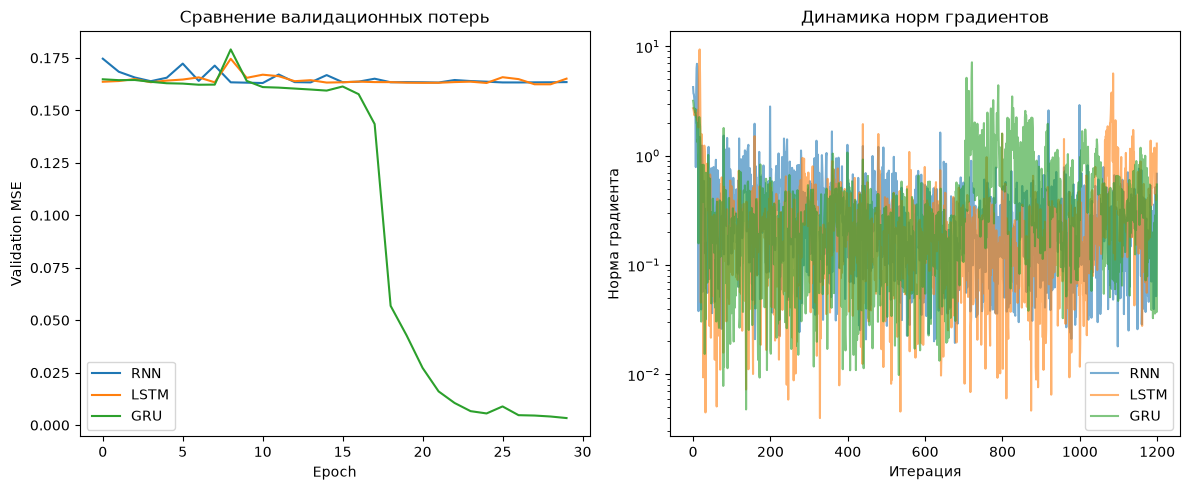

In [10]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(rnn_val_loss, label='RNN')
plt.plot(lstm_val_loss, label='LSTM')
plt.plot(gru_val_loss, label='GRU')
plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.legend()
plt.title('Сравнение валидационных потерь')

plt.subplot(1,2,2)
plt.plot(rnn_grads[:len(rnn_grads)], label='RNN', alpha=0.6)
plt.plot(lstm_grads[:len(lstm_grads)], label='LSTM', alpha=0.6)
plt.plot(gru_grads[:len(gru_grads)], label='GRU', alpha=0.6)
plt.xlabel('Итерация')
plt.ylabel('Норма градиента')
plt.yscale('log')
plt.legend()
plt.title('Динамика норм градиентов')
plt.tight_layout()
plt.show()

Теоретически надо было бы построить график такого плана:

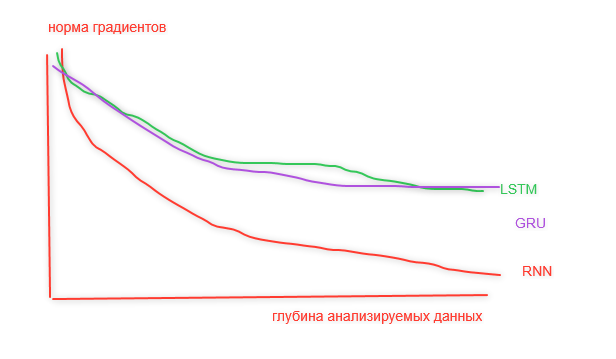

**Задание для интерпретации:**
1. Какая модель показала наименьшую ошибку на валидации? Почему, на ваш взгляд?
2. Посмотрите на график норм градиентов. Для какой модели градиенты быстрее всего уменьшаются? Связано ли это с проблемой затухания?
3. Попробуйте увеличить длину последовательности до 200 (сгенерируйте новые данные) и повторите обучение (измените `seq_len=200` в ячейке генерации). Что изменилось?

1. На последовательностях длины 100 лучший результат показала GRU: к 30-й эпохе validation MSE снизилась до 0.0034, тогда как RNN и LSTM остались около 0.16. Механизмы обновления и сброса GRU помогают сохранять отмеченные значения на длинном интервале; в данном запуске GRU также оказалась проще для оптимизации, чем LSTM.

2. Явного монотонного уменьшения ни у одной модели нет: общие нормы градиентов по мини-батчам колеблются примерно в одном диапазоне. По этому графику нельзя заключить, что у конкретной модели градиент быстрее затухает. Для прямого анализа затухания следовало бы сохранять градиенты скрытых состояний отдельно для каждого шага времени, а не только общую норму параметров после backpropagation.


In [11]:
seq_len = 200
train_X, train_y = generate_adding_problem_data(5000, seq_len)
val_X, val_y = generate_adding_problem_data(1000, seq_len)

print(f'Train shape: {train_X.shape}, Val shape: {val_X.shape}')

Train shape: (5000, 200, 2), Val shape: (1000, 200, 2)


In [12]:
batch_size = 128
train_dataset = AddingDataset(train_X, train_y)
val_dataset = AddingDataset(val_X, val_y)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [13]:
input_size = 2
hidden_size = 128
output_size = 1
epochs = 30

print("Training Vanilla RNN...")
rnn_model = VanillaRNN(input_size, hidden_size, output_size)
rnn_train_loss, rnn_val_loss, rnn_grads = train_model(rnn_model, train_loader, val_loader, epochs=epochs, use_scheduler=True)

print("\nTraining LSTM...")
lstm_model = LSTMModel(input_size, hidden_size, output_size)
lstm_train_loss, lstm_val_loss, lstm_grads = train_model(lstm_model, train_loader, val_loader, epochs=epochs, use_scheduler=True)

print("\nTraining GRU...")
gru_model = GRUModel(input_size, hidden_size, output_size)
gru_train_loss, gru_val_loss, gru_grads = train_model(gru_model, train_loader, val_loader, epochs=epochs, use_scheduler=True)

Training Vanilla RNN...
Epoch 5: train_loss=0.1705, val_loss=0.1659
Epoch 10: train_loss=0.1697, val_loss=0.1632
Epoch 15: train_loss=0.1664, val_loss=0.1627
Epoch 20: train_loss=0.1676, val_loss=0.1628
Epoch 25: train_loss=0.1701, val_loss=0.1627
Epoch 30: train_loss=0.1680, val_loss=0.1627

Training LSTM...
Epoch 5: train_loss=0.1706, val_loss=0.1676
Epoch 10: train_loss=0.1735, val_loss=0.1641
Epoch 15: train_loss=0.1696, val_loss=0.1630
Epoch 20: train_loss=0.1712, val_loss=0.1625
Epoch 25: train_loss=0.1671, val_loss=0.1625
Epoch 30: train_loss=0.1682, val_loss=0.1625

Training GRU...
Epoch 5: train_loss=0.1728, val_loss=0.1642
Epoch 10: train_loss=0.1685, val_loss=0.1628
Epoch 15: train_loss=0.1655, val_loss=0.1618
Epoch 20: train_loss=0.1691, val_loss=0.1614
Epoch 25: train_loss=0.1689, val_loss=0.1625
Epoch 30: train_loss=0.1674, val_loss=0.1611


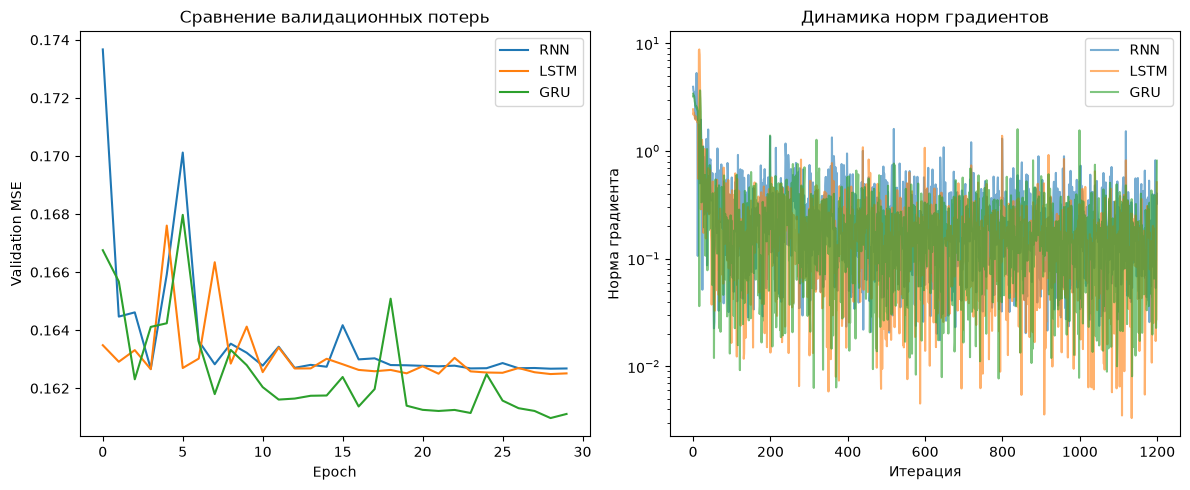

In [14]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(rnn_val_loss, label='RNN')
plt.plot(lstm_val_loss, label='LSTM')
plt.plot(gru_val_loss, label='GRU')
plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.legend()
plt.title('Сравнение валидационных потерь')

plt.subplot(1,2,2)
plt.plot(rnn_grads[:len(rnn_grads)], label='RNN', alpha=0.6)
plt.plot(lstm_grads[:len(lstm_grads)], label='LSTM', alpha=0.6)
plt.plot(gru_grads[:len(gru_grads)], label='GRU', alpha=0.6)
plt.xlabel('Итерация')
plt.ylabel('Норма градиента')
plt.yscale('log')
plt.legend()
plt.title('Динамика норм градиентов')
plt.tight_layout()
plt.show()

3. При увеличении длины до 200 преимущество GRU исчезло: к 30-й эпохе validation MSE составила 0.1627 для RNN, 0.1625 для LSTM и 0.1611 для GRU. То есть за заданные 30 эпох ни одна модель не выучила зависимость; особенно заметно ухудшилась GRU по сравнению с результатом 0.0034 при длине 100. Более длинная последовательность усложнила перенос двух отмеченных значений до финального состояния.

## **3. Эксперимент 2: Классификация тональности  комментариев на русском языке (RuSentiment)**

Используем датасет RuSentiment (отзывы о фильмах, размеченные по тональности: положительные, отрицательные, нейтральные).

**Задача:** обучить BiLSTM для классификации текста. Сравним однонаправленную LSTM и двунаправленную (BiLSTM), визуализируем скрытые состояния через t-SNE.

Labels meaning
0: NEUTRAL
1: POSITIVE
2: NEGATIVE

In [15]:
# Загружаем датасет с Hugging Face
dataset = load_dataset('Megnis/ru_sentiment_dataset-50000')
print(dataset)

from collections import Counter
all_data = list(dataset['train'])
all_labels = [ex['sentiment'] for ex in all_data]
print(Counter(all_labels))

# Стратифицированное разделение 80/10/10 без утечки между выборками
train_data, temp_data = train_test_split(
    all_data, test_size=0.2, random_state=42, stratify=all_labels
)
temp_labels = [ex['sentiment'] for ex in temp_data]
val_data, test_data = train_test_split(
    temp_data, test_size=0.5, random_state=42, stratify=temp_labels
)

print(f"Train size: {len(train_data)}, Val size: {len(val_data)}, Test size: {len(test_data)}")

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'text', 'sentiment'],
        num_rows: 48212
    })
})
Counter({2: 16158, 0: 16054, 1: 16000})
Train size: 38569, Val size: 4821, Test size: 4822


In [16]:
# Используем простой токенизатор на основе пробелов
def simple_tokenize(text, max_len=50):
    tokens = text.lower().split()[:max_len]
    return tokens

# Строим словарь только по обучающей выборке
vocab = {'<PAD>': 0, '<UNK>': 1}
for example in train_data:
    for token in simple_tokenize(example['text']):
        if token not in vocab:
            vocab[token] = len(vocab)

vocab_size = len(vocab)
print(f'Vocabulary size: {vocab_size}')

Vocabulary size: 202739


In [17]:
def text_to_ids(text, max_len=50):
    tokens = simple_tokenize(text, max_len)
    ids = [vocab.get(token, 1) for token in tokens]
    if len(ids) < max_len:
        ids += [0] * (max_len - len(ids))
    return ids[:max_len]

class RuSentimentDataset(Dataset):
    def __init__(self, data_list, max_len=50):
        self.texts = [ex['text'] for ex in data_list]
        self.labels = [ex['sentiment'] for ex in data_list]
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        ids = text_to_ids(self.texts[idx], self.max_len)
        return torch.tensor(ids, dtype=torch.long), torch.tensor(self.labels[idx], dtype=torch.long)

train_ds = RuSentimentDataset(train_data)
val_ds = RuSentimentDataset(val_data)
test_ds = RuSentimentDataset(test_data)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64)
test_loader = DataLoader(test_ds, batch_size=64)

In [18]:
class LSTMSentiment(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim, n_layers=1, bidirectional=False, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, n_layers, batch_first=True,
                            bidirectional=bidirectional, dropout=dropout if n_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_dim * (2 if bidirectional else 1), output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        embedded = self.embedding(x)
        lstm_out, (hidden, _) = self.lstm(embedded)
        if self.lstm.bidirectional:
            hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden = hidden[-1,:,:]
        hidden = self.dropout(hidden)
        out = self.fc(hidden)
        return out

# Параметры
embed_dim = 100
hidden_dim = 128
output_dim = 3  # три класса: neutral, positive, negative

model_uni = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=False).to(device)
model_bi = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=True).to(device)

In [19]:
def train_sentiment(model, train_loader, val_loader, epochs=10, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, val_accs = [], []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs}')
        for X_batch, y_batch in pbar:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            pbar.set_postfix({'loss': loss.item()})
        train_losses.append(total_loss / len(train_loader))

        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                pred = model(X_batch)
                _, predicted = torch.max(pred, 1)
                total += y_batch.size(0)
                correct += (predicted == y_batch).sum().item()
        val_acc = correct / total
        val_accs.append(val_acc)
        print(f'Epoch {epoch+1}: avg_train_loss={train_losses[-1]:.4f}, val_acc={val_acc:.4f}')

    return train_losses, val_accs

print("Training unidirectional LSTM...")
uni_loss, uni_acc = train_sentiment(model_uni, train_loader, val_loader, epochs=10)

print("\nTraining bidirectional LSTM...")
bi_loss, bi_acc = train_sentiment(model_bi, train_loader, val_loader, epochs=10)

Training unidirectional LSTM...


Epoch 1/10: 100%|██████████| 603/603 [00:12<00:00, 46.73it/s, loss=1.12]


Epoch 1: avg_train_loss=1.0469, val_acc=0.4848


Epoch 2/10: 100%|██████████| 603/603 [00:12<00:00, 47.92it/s, loss=1.12]


Epoch 2: avg_train_loss=0.9862, val_acc=0.5038


...

Epoch 8: avg_train_loss=0.0469, val_acc=0.6250


Epoch 9/10: 100%|██████████| 603/603 [00:14<00:00, 41.50it/s, loss=0.063]


Epoch 9: avg_train_loss=0.0405, val_acc=0.6314


Epoch 10/10: 100%|██████████| 603/603 [00:14<00:00, 43.07it/s, loss=0.00911]


Epoch 10: avg_train_loss=0.0348, val_acc=0.6132


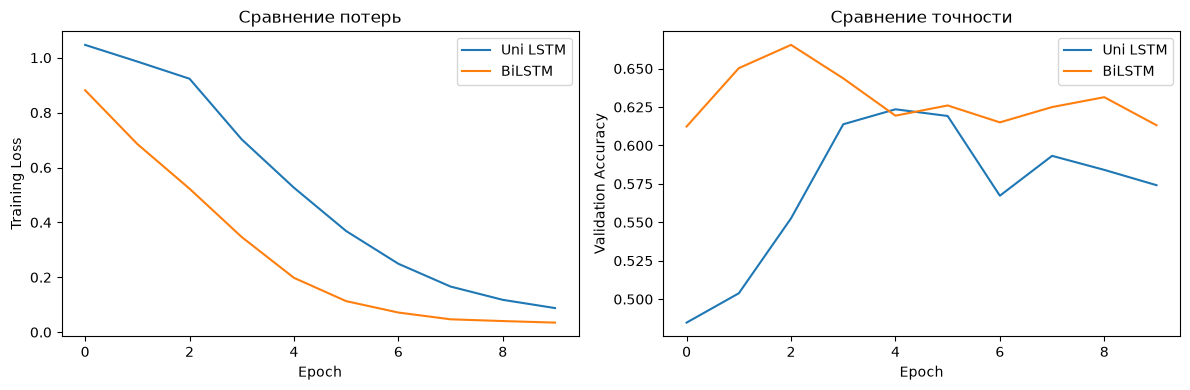

In [20]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(uni_loss, label='Uni LSTM')
plt.plot(bi_loss, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.legend()
plt.title('Сравнение потерь')

plt.subplot(1,2,2)
plt.plot(uni_acc, label='Uni LSTM')
plt.plot(bi_acc, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.title('Сравнение точности')
plt.tight_layout()
plt.show()

Test accuracy UniLSTM: 0.5718
Test accuracy BiLSTM:  0.6286

Classification report (BiLSTM):
              precision    recall  f1-score   support

     neutral     0.6450    0.4085    0.5002      1606
    positive     0.5694    0.7538    0.6487      1600
    negative     0.6929    0.7234    0.7078      1616

    accuracy                         0.6286      4822
   macro avg     0.6358    0.6285    0.6189      4822
weighted avg     0.6360    0.6286    0.6191      4822



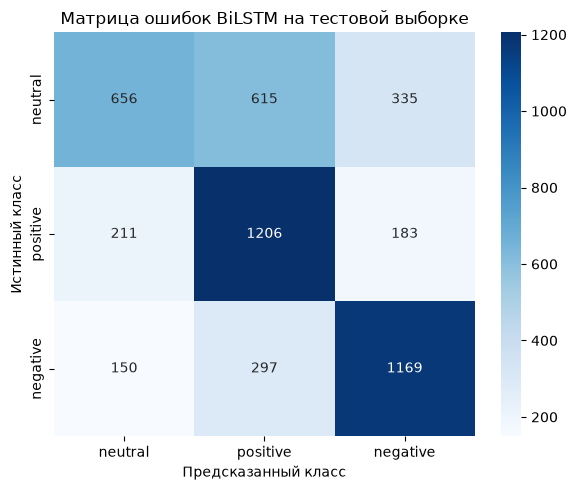

In [21]:
def evaluate_sentiment(model, data_loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            logits = model(X_batch.to(device))
            y_true.extend(y_batch.numpy())
            y_pred.extend(logits.argmax(dim=1).cpu().numpy())
    return accuracy_score(y_true, y_pred), np.asarray(y_true), np.asarray(y_pred)

uni_test_acc, uni_true, uni_pred = evaluate_sentiment(model_uni, test_loader)
bi_test_acc, bi_true, bi_pred = evaluate_sentiment(model_bi, test_loader)
print(f"Test accuracy UniLSTM: {uni_test_acc:.4f}")
print(f"Test accuracy BiLSTM:  {bi_test_acc:.4f}")
print("\nClassification report (BiLSTM):")
print(classification_report(bi_true, bi_pred, target_names=['neutral', 'positive', 'negative'], digits=4))

cm = confusion_matrix(bi_true, bi_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['neutral', 'positive', 'negative'],
            yticklabels=['neutral', 'positive', 'negative'])
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок BiLSTM на тестовой выборке')
plt.tight_layout()
plt.show()

### **3.1. Визуализация скрытых состояний с помощью t-SNE (3 класса)**

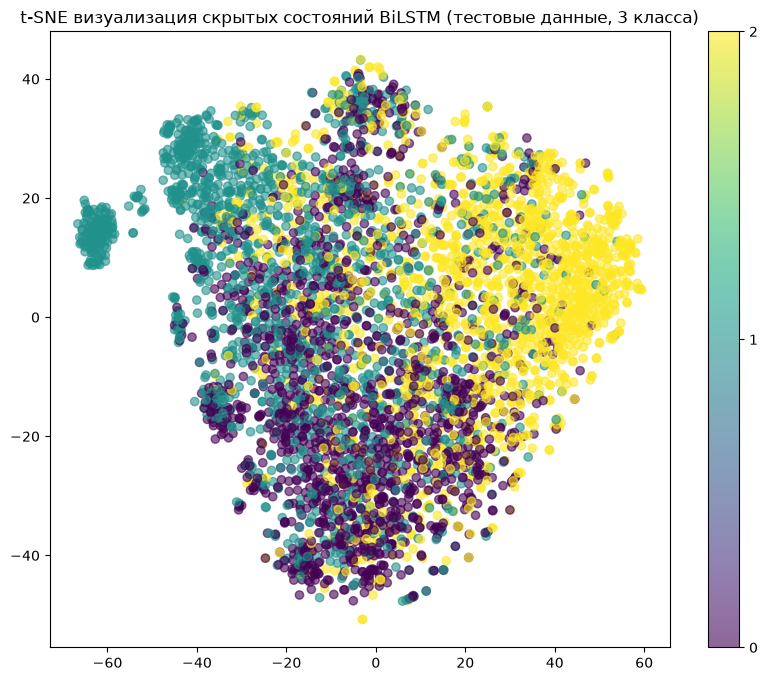

In [22]:
model_bi.eval()
hidden_states = []
labels = []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        embedded = model_bi.embedding(X_batch)
        lstm_out, (hidden, _) = model_bi.lstm(embedded)
        if model_bi.lstm.bidirectional:
            hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden = hidden[-1,:,:]
        hidden_states.append(hidden.cpu().numpy())
        labels.append(y_batch.numpy())

hidden_states = np.vstack(hidden_states)
labels = np.hstack(labels)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
hidden_2d = tsne.fit_transform(hidden_states)

plt.figure(figsize=(10,8))
scatter = plt.scatter(hidden_2d[:,0], hidden_2d[:,1], c=labels, cmap='viridis', alpha=0.6)
plt.colorbar(scatter, ticks=[0,1,2])
plt.title('t-SNE визуализация скрытых состояний BiLSTM (тестовые данные, 3 класса)')
plt.show()

**Задание для интерпретации:**
1. Сравните точность однонаправленной и двунаправленной LSTM. Какая модель оказалась лучше и почему?
2. Посмотрите на t-SNE проекцию. Видны ли кластеры, соответствующие разным классам? Если нет, то что это может означать? Можно ли как-то эту информацию использовать?
3. (Дополнительно) Попробуйте изменить размер скрытого состояния (`hidden_dim`) и количество слоёв LSTM (`n_layers`). Как это влияет на точность и время обучения?

1. BiLSTM оказалась лучше: максимальная validation accuracy равна 0.6654 против 0.6235 у UniLSTM; на независимой тестовой выборке итоговые модели получили 0.6286 и 0.5718 соответственно. Двунаправленная модель учитывает контекст как слева, так и справа, что полезно для распознавания тональности. Снижение validation accuracy на поздних эпохах при продолжающемся уменьшении training loss указывает на переобучение.

2. На t-SNE видна частичная разделимость: для классов 1 и 2 есть выраженные области, но в центре классы заметно пересекаются, особенно с нейтральным классом 0. Это согласуется с умеренной test accuracy и показывает наличие неоднозначных примеров. Проекцию можно использовать для анализа ошибок и выбросов, но не как самостоятельное доказательство качества, поскольку t-SNE искажает глобальные расстояния.

In [23]:
# Параметры
embed_dim = 100
hidden_dim = 256
output_dim = 3  # три класса: neutral, positive, negative

model_uni = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=False, n_layers=2).to(device)
model_bi = LSTMSentiment(vocab_size, embed_dim, hidden_dim, output_dim, bidirectional=True,n_layers=2).to(device)

In [24]:
print("Training unidirectional LSTM...")
uni_loss, uni_acc = train_sentiment(model_uni, train_loader, val_loader, epochs=10)

print("\nTraining bidirectional LSTM...")
bi_loss, bi_acc = train_sentiment(model_bi, train_loader, val_loader, epochs=10)

Training unidirectional LSTM...


Epoch 1/10: 100%|██████████| 603/603 [00:18<00:00, 32.44it/s, loss=0.959]


Epoch 1: avg_train_loss=1.0263, val_acc=0.4642


Epoch 2/10: 100%|██████████| 603/603 [00:18<00:00, 33.35it/s, loss=1.1]


Epoch 2: avg_train_loss=0.9949, val_acc=0.5584


...

Epoch 8: avg_train_loss=0.0838, val_acc=0.6509


Epoch 9/10: 100%|██████████| 603/603 [00:27<00:00, 22.02it/s, loss=0.194]


Epoch 9: avg_train_loss=0.0651, val_acc=0.6463


Epoch 10/10: 100%|██████████| 603/603 [00:27<00:00, 22.11it/s, loss=0.0569]


Epoch 10: avg_train_loss=0.0507, val_acc=0.6484


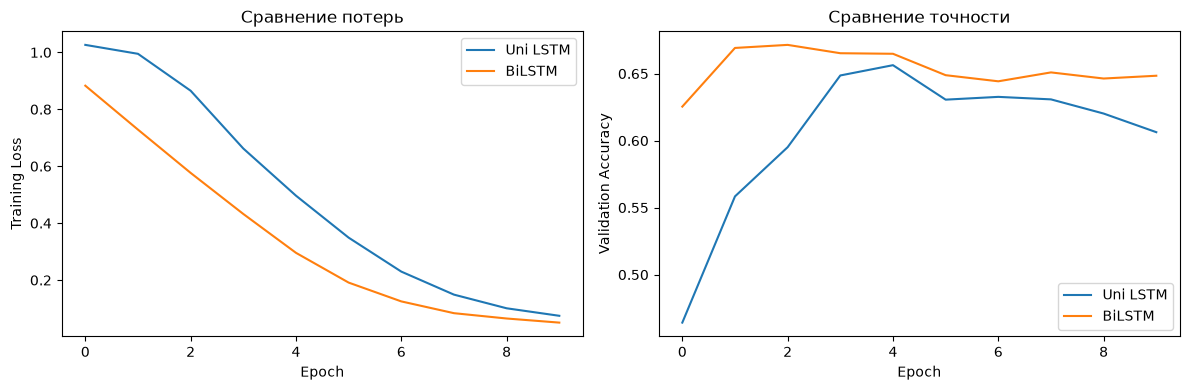

In [25]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(uni_loss, label='Uni LSTM')
plt.plot(bi_loss, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.legend()
plt.title('Сравнение потерь')

plt.subplot(1,2,2)
plt.plot(uni_acc, label='Uni LSTM')
plt.plot(bi_acc, label='BiLSTM')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.title('Сравнение точности')
plt.tight_layout()
plt.show()

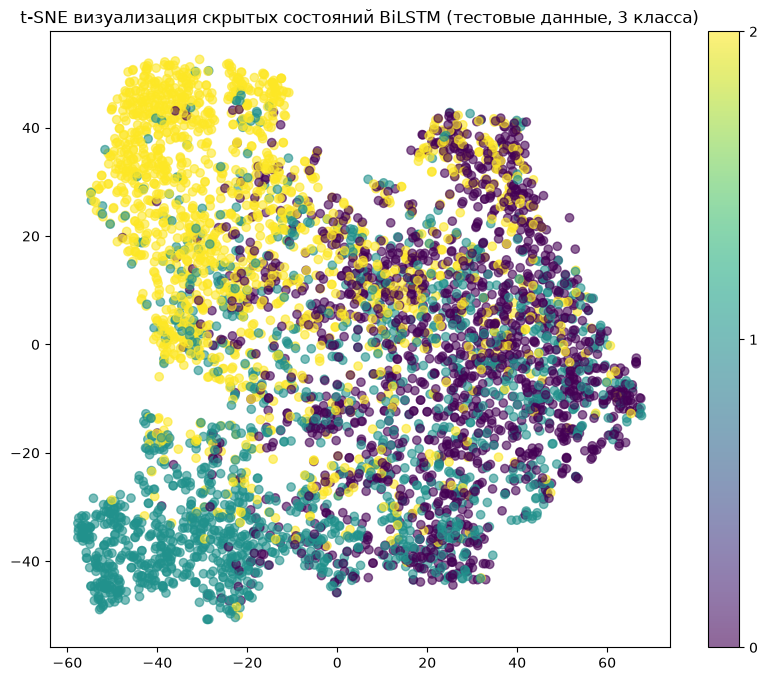

In [26]:
model_bi.eval()
hidden_states = []
labels = []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        embedded = model_bi.embedding(X_batch)
        lstm_out, (hidden, _) = model_bi.lstm(embedded)
        if model_bi.lstm.bidirectional:
            hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden = hidden[-1,:,:]
        hidden_states.append(hidden.cpu().numpy())
        labels.append(y_batch.numpy())

hidden_states = np.vstack(hidden_states)
labels = np.hstack(labels)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
hidden_2d = tsne.fit_transform(hidden_states)

plt.figure(figsize=(10,8))
scatter = plt.scatter(hidden_2d[:,0], hidden_2d[:,1], c=labels, cmap='viridis', alpha=0.6)
plt.colorbar(scatter, ticks=[0,1,2])
plt.title('t-SNE визуализация скрытых состояний BiLSTM (тестовые данные, 3 класса)')
plt.show()

3. При `hidden_dim=256` и `n_layers=2` максимальная validation accuracy немного выросла: с 0.6235 до 0.6563 у UniLSTM и с 0.6654 до 0.6714 у BiLSTM. Среднее время эпохи выросло примерно с 13 до 18 секунд для UniLSTM и с 14 до 27 секунд для BiLSTM. После пика accuracy снова снижается, поэтому увеличение ёмкости не устраняет переобучение.

## **Заключение**

В этом практическом занятии мы:
- Сравнили RNN, LSTM и GRU на задаче долгосрочной зависимости: GRU успешно решила задачу при длине 100, но при длине 200 все три модели за 30 эпох остались около базового уровня ошибки.
- Визуализировали общие нормы градиентов и обсудили, почему для диагностики затухания по времени нужны градиенты отдельных скрытых состояний.
- Применили BiLSTM для классификации русскоязычных текстов и сравнили с однонаправленной версией.
- Использовали t-SNE для визуализации скрытых представлений.

Попробуйте поэкспериментировать с гиперпараметрами и, возможно, применить предобученные эмбеддинги (FastText) для улучшения качества.

### Рефлексия

В ходе работы я научился формировать последовательные данные для adding problem, обучать и сравнивать RNN, LSTM и GRU, контролировать нормы градиентов и применять gradient clipping. Также я построил однонаправленную и двунаправленную LSTM для классификации русскоязычных текстов, оценил модели на независимой тестовой выборке и визуализировал скрытые состояния с помощью t-SNE.

Материал изложен последовательно и хорошо связывает теорию с экспериментом. Для улучшения блокнота полезно добавить краткое объяснение ограничений t-SNE, явную проверку отсутствия утечки данных и автоматический вывод итоговой таблицы метрик.